# 01 - Exploring the batch files

First look at the three MATR batch files (Severson et al. 2019). Goal: understand how the data is stored before building any tables.

Files are MATLAB v7.3, which is HDF5, so I open them with h5py.

In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

DATA = "../data/raw/"
FILES = {
    "b1": DATA + "2017-05-12_batchdata.mat",
    "b2": DATA + "2017-06-30_batchdata.mat",
    "b3": DATA + "2018-04-12_batchdata.mat",
}
files = {name: h5py.File(path, "r") for name, path in FILES.items()}

f = files["b1"]
b = f["batch"]
print(list(b.keys()))

['Vdlin', 'barcode', 'channel_id', 'cycle_life', 'cycles', 'policy', 'policy_readable', 'summary']


Every field in `batch` has one row per cell, but the rows are **references**, not values. To get the value you have to open the reference with `f[ref]`. Small helpers so I don't repeat this everywhere:

In [2]:
def get_value(f, field, i):
    # number stored behind a reference, e.g. cycle_life of cell i
    ref = f["batch"][field][i, 0]
    return f[ref][()].item()


def get_text(f, field, i):
    # text is stored as character codes
    ref = f["batch"][field][i, 0]
    return "".join(chr(c) for c in f[ref][()].flatten())


def get_summary(f, i):
    # per-cycle summary values of cell i, as a dict of 1D arrays
    group = f[f["batch"]["summary"][i, 0]]
    return {key: group[key][0, :] for key in group.keys()}


print(get_value(f, "cycle_life", 0))
print(get_text(f, "policy_readable", 0))
print(get_summary(f, 0).keys())

1190.0
3.6C(80%)-3.6C
dict_keys(['IR', 'QCharge', 'QDischarge', 'Tavg', 'Tmax', 'Tmin', 'chargetime', 'cycle'])


## How many cells per batch?

In [3]:
for name, f in files.items():
    n = f["batch"]["cycle_life"].shape[0]
    print(name, n, "cells")

b1 46 cells
b2 48 cells
b3 46 cells


## Cycle life per cell

Cycle life = number of cycles until capacity drops to 80% of nominal (0.88 Ah for these 1.1 Ah cells).

In [4]:
for name, f in files.items():
    n = f["batch"]["cycle_life"].shape[0]
    lives = np.array([get_value(f, "cycle_life", i) for i in range(n)])
    missing = np.where(np.isnan(lives))[0]
    print(f"{name}: min {np.nanmin(lives):.0f}, max {np.nanmax(lives):.0f}, missing cycle_life for cells {missing.tolist()}")

b1: min 534, max 1227, missing cycle_life for cells []
b2: min 148, max 1061, missing cycle_life for cells []
b3: min 541, max 1935, missing cycle_life for cells [23, 32]


## Does the summary length match the cycle life?

In [5]:
for name, f in files.items():
    n = f["batch"]["cycle_life"].shape[0]
    diffs = []
    for i in range(n):
        life = get_value(f, "cycle_life", i)
        n_cycles = len(get_summary(f, i)["cycle"])
        diffs.append(n_cycles - life)
    diffs = np.array(diffs)
    print(name, "summary length minus cycle_life:", np.unique(diffs[~np.isnan(diffs)]).astype(int))

b1 summary length minus cycle_life: [-1]
b2 summary length minus cycle_life: [-1 20 21 22 23 24 25 26 27 28 29 31 32 33 34 35 36 37]
b3 summary length minus cycle_life: [-1]


## Discharge capacity over the cycles

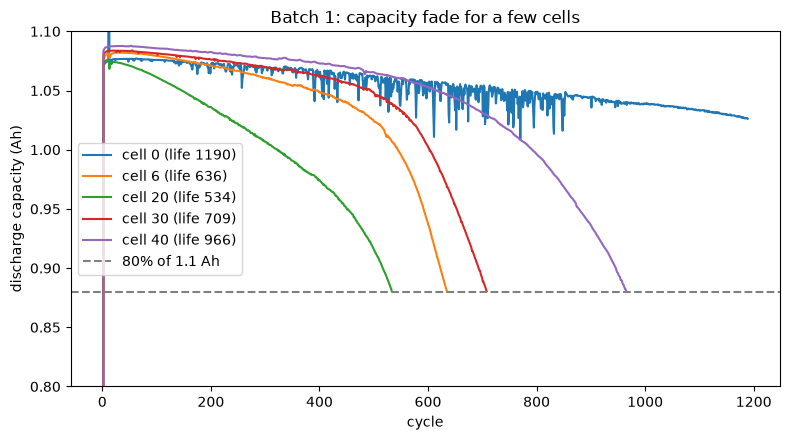

In [6]:
f = files["b1"]
fig, ax = plt.subplots(figsize=(8, 4.5))
for i in [0, 6, 20, 30, 40]:
    s = get_summary(f, i)
    life = get_value(f, "cycle_life", i)
    ax.plot(s["cycle"], s["QDischarge"], label=f"cell {i} (life {life:.0f})")
ax.axhline(0.88, color="grey", linestyle="--", label="80% of 1.1 Ah")
ax.set_xlabel("cycle")
ax.set_ylabel("discharge capacity (Ah)")
ax.set_ylim(0.8, 1.1)
ax.set_title("Batch 1: capacity fade for a few cells")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/capacity_fade_batch1.png", dpi=120)
plt.show()

In [7]:
# capacity at the last cycle before end of life, should be close to 0.88
f = files["b1"]
for i in [0, 6, 20]:
    s = get_summary(f, i)
    life = int(get_value(f, "cycle_life", i))
    print(i, "capacity around end of life:", s["QDischarge"][life - 3:life].round(3))

0 capacity around end of life: [1.027 1.026]


6 capacity around end of life: [0.881 0.88 ]
20 capacity around end of life: [0.883 0.881]


Cell 0 ends at 1.03 Ah, nowhere near 0.88. So its cycle_life of 1190 can't be a real end of life. Which batch 1 cells never reach 80%?

In [8]:
f = files["b1"]
for i in range(46):
    q = get_summary(f, i)["QDischarge"]
    if q[-1] > 0.9:
        print(f"b1 cell {i:2d}: last capacity {q[-1]:.3f} Ah after {len(q)} cycles, policy {get_text(f, 'policy_readable', i)}")

b1 cell  0: last capacity 1.026 Ah after 1189 cycles, policy 3.6C(80%)-3.6C
b1 cell  1: last capacity 1.038 Ah after 1178 cycles, policy 3.6C(80%)-3.6C
b1 cell  2: last capacity 1.043 Ah after 1176 cycles, policy 3.6C(80%)-3.6C
b1 cell  3: last capacity 0.971 Ah after 1225 cycles, policy 4C(80%)-4C
b1 cell  4: last capacity 1.022 Ah after 1226 cycles, policy 4C(80%)-4C
b1 cell  8: last capacity 0.969 Ah after 878 cycles, policy 5.4C(40%)-3.6C
b1 cell 10: last capacity 0.961 Ah after 905 cycles, policy 5.4C(50%)-3C
b1 cell 12: last capacity 0.913 Ah after 901 cycles, policy 5.4C(50%)-3.6C
b1 cell 13: last capacity 0.923 Ah after 896 cycles, policy 5.4C(50%)-3.6C
b1 cell 22: last capacity 0.963 Ah after 890 cycles, policy 6C(30%)-3.6C


Some batch 2 cells start with a capacity that is already low, which a new cell wouldn't have. Are these the same cells, continued?

In [9]:
f = files["b2"]
for i in range(48):
    q = get_summary(f, i)["QDischarge"]
    if q[0] < 1.04:
        print(f"b2 cell {i:2d}: first capacity {q[0]:.3f} Ah, policy text '{get_text(f, 'policy_readable', i)}'")

b2 cell  7: first capacity 1.022 Ah, policy text '80%)-3.6C'
b2 cell  8: first capacity 1.025 Ah, policy text '80%)-3.6C'
b2 cell  9: first capacity 1.030 Ah, policy text '80%)-3.6C'
b2 cell 15: first capacity 0.972 Ah, policy text '80%)-4C'
b2 cell 16: first capacity 1.007 Ah, policy text '80%)-4C'
b2 cell 47: first capacity 1.038 Ah, policy text '6C(60%)-3C'


## The first cycle

In [10]:
for name, f in files.items():
    s = get_summary(f, 0)
    print(name, "QDischarge of first 3 cycles:", s["QDischarge"][:3].round(4))

b1 QDischarge of first 3 cycles: [0.     1.0707 1.0719]
b2 QDischarge of first 3 cycles: [1.0681 1.0701 1.0719]
b3 QDischarge of first 3 cycles: [1.0666 1.0675 1.0683]


In [11]:
# full curves: each cycle is again a reference
f = files["b1"]
cyc = f[f["batch"]["cycles"][0, 0]]
print(list(cyc.keys()))
for k in range(4):
    print("cycle index", k, "Qd points:", f[cyc["Qd"][k, 0]].shape)

['I', 'Qc', 'Qd', 'Qdlin', 'T', 'Tdlin', 'V', 'discharge_dQdV', 't']
cycle index 0 Qd points: (2,)
cycle index 1 Qd points: (1, 1087)
cycle index 2 Qd points: (1, 1117)
cycle index 3 Qd points: (1, 1114)


## Qdlin and Vdlin

`Qdlin` is the discharge capacity of one cycle, interpolated onto the fixed voltage grid `Vdlin` (1000 points). Because every cycle uses the same grid, two cycles can be subtracted directly. That is what ΔQ(V) in Stage 2 is built from.

Vdlin: 1000 points, from 2.0 to 3.5 V


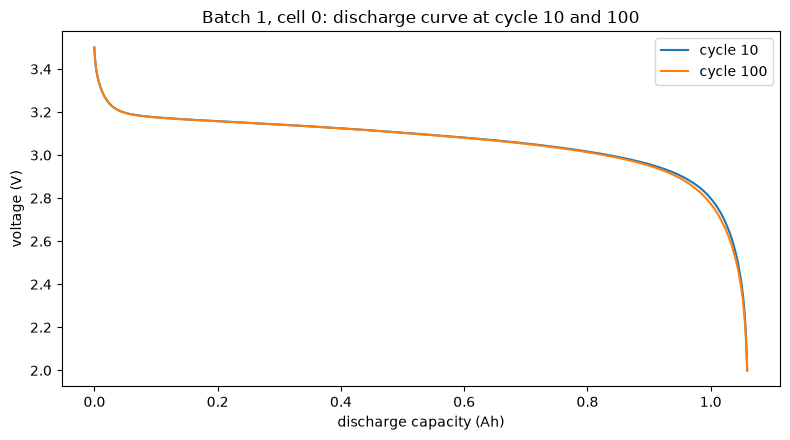

In [12]:
f = files["b1"]
V = f[f["batch"]["Vdlin"][0, 0]][()].flatten()
print("Vdlin:", len(V), "points, from", V.min().round(2), "to", V.max().round(2), "V")

def get_qdlin(f, i, cycle_index):
    cyc = f[f["batch"]["cycles"][i, 0]]
    return f[cyc["Qdlin"][cycle_index, 0]][()].flatten()

fig, ax = plt.subplots(figsize=(8, 4.5))
for c in [10, 100]:
    ax.plot(get_qdlin(f, 0, c), V, label=f"cycle {c}")
ax.set_xlabel("discharge capacity (Ah)")
ax.set_ylabel("voltage (V)")
ax.set_title("Batch 1, cell 0: discharge curve at cycle 10 and 100")
ax.legend()
plt.tight_layout()
plt.show()

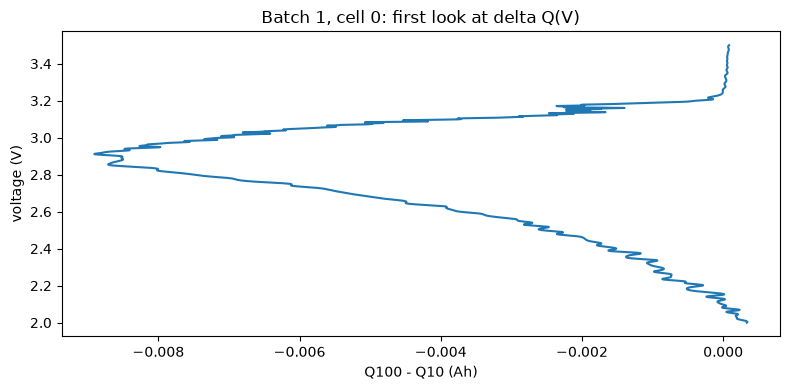

In [13]:
f = files["b1"]
dq = get_qdlin(f, 0, 100) - get_qdlin(f, 0, 10)
plt.figure(figsize=(8, 4))
plt.plot(dq, V)
plt.xlabel("Q100 - Q10 (Ah)")
plt.ylabel("voltage (V)")
plt.title("Batch 1, cell 0: first look at delta Q(V)")
plt.tight_layout()
plt.show()

## Charging policies

In [14]:
for name, f in files.items():
    n = f["batch"]["cycle_life"].shape[0]
    policies = {get_text(f, "policy_readable", i) for i in range(n)}
    print(name, len(policies), "different policies, e.g.", sorted(policies)[:3])

b1 23 different policies, e.g. ['3.6C(80%)-3.6C', '4.4C(80%)-4.4C', '4.8C(80%)-4.8C']
b2 43 different policies, e.g. ['1C(4%)-6C', '2C(10%)-6C', '2C(2%)-5C']
b3 8 different policies, e.g. ['3.7C(31%)-5.9C-newstructure', '4.8C(80%)-4.8C-newstructure', '5.3C(54%)-4C-newstructure']


## Notes

1. **Cells per batch:** 46, 48 and 46, so 140 in total. The paper uses 124, so 16 get dropped somewhere.
2. **Summary length vs cycle_life:** in batch 1 and 3 the summary has exactly one cycle less than cycle_life. In batch 2 many cells have 20 to 37 extra cycles, so they kept cycling after they hit 80%. When I build features I have to cut at cycle_life, not at the end of the data.
3. **Capacity fade:** flat at first, then it drops faster and faster near the end (the "knee"). Cells that look the same at cycle 100 end up with very different lifetimes, which is why early prediction is hard.
4. **Odd cells:**
   - 10 cells in batch 1 never reach 0.88 Ah. Cells 0 to 4 continue in batch 2 as cells 7, 8, 9, 15 and 16. Their first capacity in batch 2 matches the last one in batch 1, and their policy text is cut off (`80%)-3.6C`). Batch 2 cell 47 also shows up in that check, but its policy text is complete, so it looks like a new cell that just starts a bit low. The other 5 batch 1 cells (8, 10, 12, 13, 22) just stop.
   - Batch 3 cells 23 and 32 have no cycle_life (NaN). They ran over 2,000 cycles without reaching 80%.
   - That explains 12 of the 16 missing cells. The rest is for step 1.5.
5. **Qdlin / Vdlin:** Vdlin is a fixed grid of 1,000 voltages from 2.0 to 3.5 V, and Qdlin is each cycle's discharge capacity on that grid. Because the grid is the same for every cycle, I can subtract two cycles directly, e.g. Q100 minus Q10.
6. **First cycle:** in batch 1 the first cycle is basically empty (capacity 0, only 2 data points). Batch 2 and 3 look normal. Start from cycle index 1 (the second cycle) to be safe.

Also: batch 3 policies end in `-newstructure`, probably a change in the test setup. Worth remembering for the later-batch test.